In [1]:
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = "sync_marker_log_20260707_173943.csv"

In [2]:
df = pd.read_csv(CSV_PATH)
df["Timestamp"] = pd.to_datetime(df["Timestamp"], format="%Y-%m-%d %H:%M:%S.%f")
df.head()

,Timestamp,Sync_Data,User_Marker
0,2026-07-07 17:39:43.007,0,0
1,2026-07-07 17:39:43.017,0,0
2,2026-07-07 17:39:43.027,0,0
3,2026-07-07 17:39:43.037,0,0
4,2026-07-07 17:39:43.047,0,0


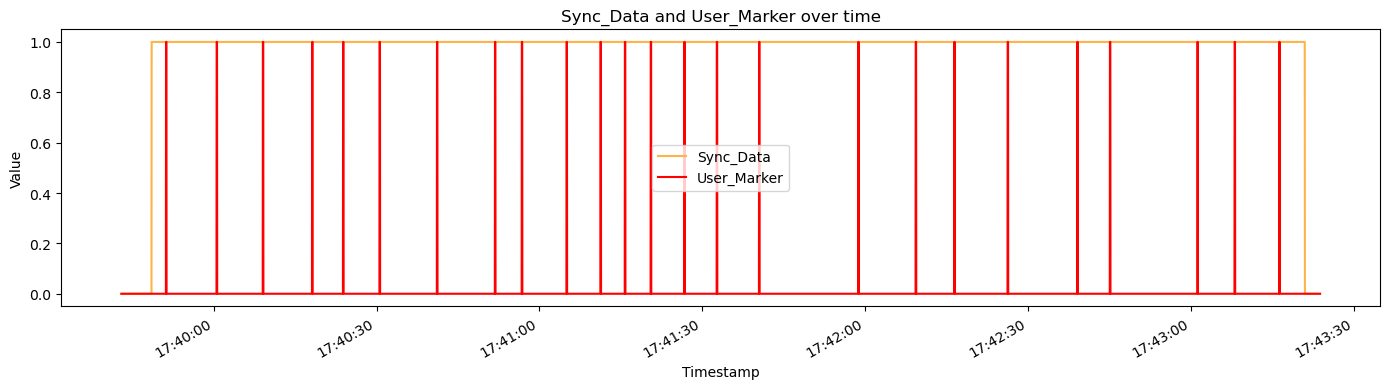

In [3]:
fig, ax = plt.subplots(figsize=(14, 4))

# .to_numpy() avoids a pandas/matplotlib datetime-indexing incompatibility
# on older matplotlib versions.
ax.plot(df["Timestamp"].to_numpy(), df["Sync_Data"].to_numpy(), color="#FFB347", label="Sync_Data")
ax.plot(df["Timestamp"].to_numpy(), df["User_Marker"].to_numpy(), color="red", label="User_Marker")

ax.set_xlabel("Timestamp")
ax.set_ylabel("Value")
ax.set_title("Sync_Data and User_Marker over time")
ax.legend()
fig.autofmt_xdate()

plt.tight_layout()
plt.show()

In [8]:
import csv

RAW_CSV_PATH = "trial1_06.csv" 
OUTPUT_CSV_PATH = "trial1_06_rigid_bodies.csv"
TARGET_NAMES = ["TableMarker", "LinkCamera", "LinkBase", "LinkTcp"]

In [ ]:
import re
import csv
import pandas as pd



OPTITRACK_CSV_PATH = "trial1_06.csv"
LOGGER_CSV_PATH = "sync_marker_log_20260707_173943.csv"
ALIGNED_OUTPUT_PATH = "aligned_dataset.csv"


def _sanitize(name: str) -> str:
    """Collapse anything that isn't alphanumeric/underscore into a single '_'."""
    return re.sub(r"[^0-9A-Za-z]+", "_", name).strip("_")


def locate_motive_header_rows(path: str):
    """
    Locate the Type / Name / ID / Sub-type / Axis header rows of a Motive
    export by searching for the row whose second cell reads "Type", rather
    than assuming a fixed row number. This keeps the parser working even if
    the take-metadata block above it changes size.

    Returns (name_row, subtype_row, axis_row, data_start_line).
    """
    with open(path, newline="") as f:
        reader = csv.reader(f)
        rows = [row for row, _ in zip(reader, range(20))]  # header block is always small

    type_row_idx = next(i for i, row in enumerate(rows) if len(row) > 1 and row[1] == "Type")
    name_row_idx = type_row_idx + 1
    # id_row_idx = type_row_idx + 2  # asset GUID / marker ID -- not needed for flattening
    subtype_row_idx = type_row_idx + 3
    axis_row_idx = type_row_idx + 4

    name_row = rows[name_row_idx]
    subtype_row = rows[subtype_row_idx]
    axis_row = rows[axis_row_idx]
    data_start_line = axis_row_idx + 1
    return name_row, subtype_row, axis_row, data_start_line


def flatten_motive_columns(name_row, subtype_row, axis_row):
    """
    Flatten the 3-level (Name, Sub-type, Axis) Motive header into single-level
    column names, e.g. "TableMarker_Rotation_X", "LinkTcp_Marker1_Position_Y".

    The first two columns (Frame, Time (Seconds)) aren't tied to any rigid
    body: their Name/Sub-type header cells hold row labels ("Name", "ID", ...)
    rather than being blank, so only the Axis-row text is meaningful there.

    Falls back to a numeric suffix if two source columns flatten to the same
    name (Motive exports both a per-rigid-body marker position and a
    duplicate top-level "Marker" entry for the same physical marker).
    """
    seen = {}
    flat_names = []
    for i, (name, subtype, axis) in enumerate(zip(name_row, subtype_row, axis_row)):
        if i < 2:
            parts = [axis.strip()]
        else:
            parts = [p.strip() for p in (name, subtype, axis) if p and p.strip()]
        col = _sanitize("_".join(parts))

        if col in seen:
            seen[col] += 1
            col = f"{col}_{seen[col]}"
        else:
            seen[col] = 1
        flat_names.append(col)
    return flat_names


def load_optitrack(path: str) -> pd.DataFrame:
    """Read a Motive export CSV, flattening its MultiIndex header into
    single-level column names, without altering any pose values."""
    name_row, subtype_row, axis_row, data_start_line = locate_motive_header_rows(path)
    flat_names = flatten_motive_columns(name_row, subtype_row, axis_row)
    return pd.read_csv(path, skiprows=data_start_line, header=None, names=flat_names)


def load_logger(path: str) -> pd.DataFrame:
    """Read the sync-marker logger CSV and parse its Timestamp column."""
    logger_df = pd.read_csv(path)
    logger_df["Timestamp"] = pd.to_datetime(logger_df["Timestamp"], format="%Y-%m-%d %H:%M:%S.%f")
    return logger_df


def extract_sync_segment(logger_df: pd.DataFrame) -> pd.DataFrame:
    """Return the contiguous logger rows where Sync_Data == 1, i.e. the
    MoCap recording window (see module docstring above)."""
    return logger_df[logger_df["Sync_Data"] == 1].reset_index(drop=True)


def synchronize(opti_df: pd.DataFrame, sync_segment: pd.DataFrame) -> pd.DataFrame:
    """
    Align OptiTrack and logger samples index-for-index. No interpolation or
    resampling: if the two recordings differ by a few samples (start/stop
    jitter), both are simply trimmed to their common length before being
    concatenated column-wise.
    """
    min_len = min(len(opti_df), len(sync_segment))
    opti_trim = opti_df.iloc[:min_len].reset_index(drop=True)
    logger_trim = sync_segment.iloc[:min_len].reset_index(drop=True)

    return pd.concat(
        [logger_trim[["Timestamp", "Sync_Data", "User_Marker"]], opti_trim],
        axis=1,
    )


# ------------------------------------ Run ----------------------------------

optitrack_df = load_optitrack(OPTITRACK_CSV_PATH)
logger_df = load_logger(LOGGER_CSV_PATH)
sync_segment_df = extract_sync_segment(logger_df)
aligned_df = synchronize(optitrack_df, sync_segment_df)
aligned_df.to_csv(ALIGNED_OUTPUT_PATH, index=False)

length_mismatch = abs(len(optitrack_df) - len(sync_segment_df))
sync_ok = len(aligned_df) > 0 and length_mismatch / max(len(optitrack_df), 1) < 0.05

print(f"Total OptiTrack samples:            {len(optitrack_df)}")
print(f"Total logger samples:               {len(logger_df)}")
print(f"Logger samples with Sync_Data == 1: {len(sync_segment_df)}")
print(f"Synchronized samples (saved):       {len(aligned_df)}")
print(f"Length mismatch (Opti vs Sync==1):  {length_mismatch}")
print(f"Synchronization successful:         {sync_ok}")
print(f"Wrote {len(aligned_df)} rows -> {ALIGNED_OUTPUT_PATH}")


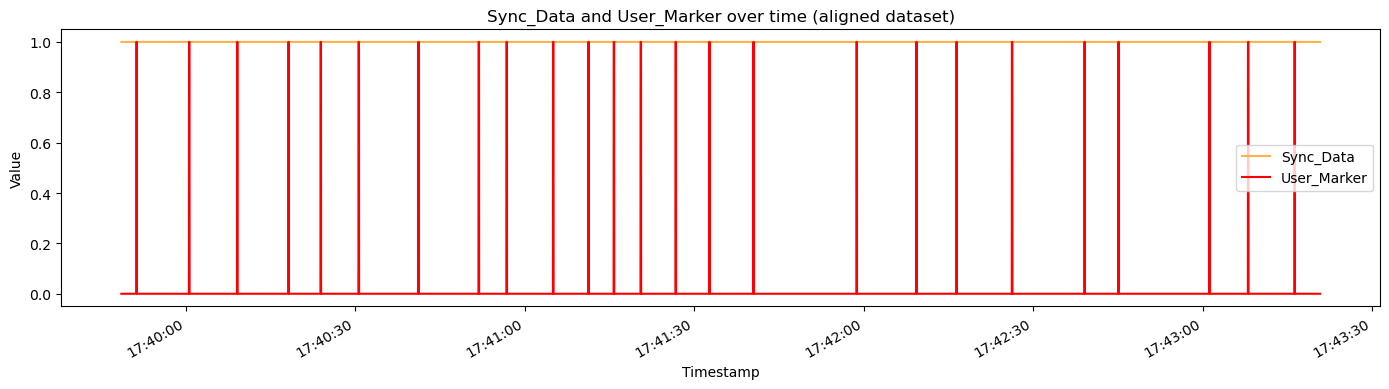

In [6]:
ALIGNED_CSV_PATH = "trial1_06_aligned_dataset.csv"

aligned_plot_df = pd.read_csv(ALIGNED_CSV_PATH, usecols=["Timestamp", "Sync_Data", "User_Marker"])
aligned_plot_df["Timestamp"] = pd.to_datetime(aligned_plot_df["Timestamp"], format="%Y-%m-%d %H:%M:%S.%f")

fig, ax = plt.subplots(figsize=(14, 4))

ax.plot(aligned_plot_df["Timestamp"].to_numpy(), aligned_plot_df["Sync_Data"].to_numpy(), color="#FFB347", label="Sync_Data")
ax.plot(aligned_plot_df["Timestamp"].to_numpy(), aligned_plot_df["User_Marker"].to_numpy(), color="red", label="User_Marker")

ax.set_xlabel("Timestamp")
ax.set_ylabel("Value")
ax.set_title("Sync_Data and User_Marker over time (aligned dataset)")
ax.legend()
fig.autofmt_xdate()

plt.tight_layout()
plt.show()


Found 25 events ([10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10])
Event 0: 10 samples, Frame 265-274


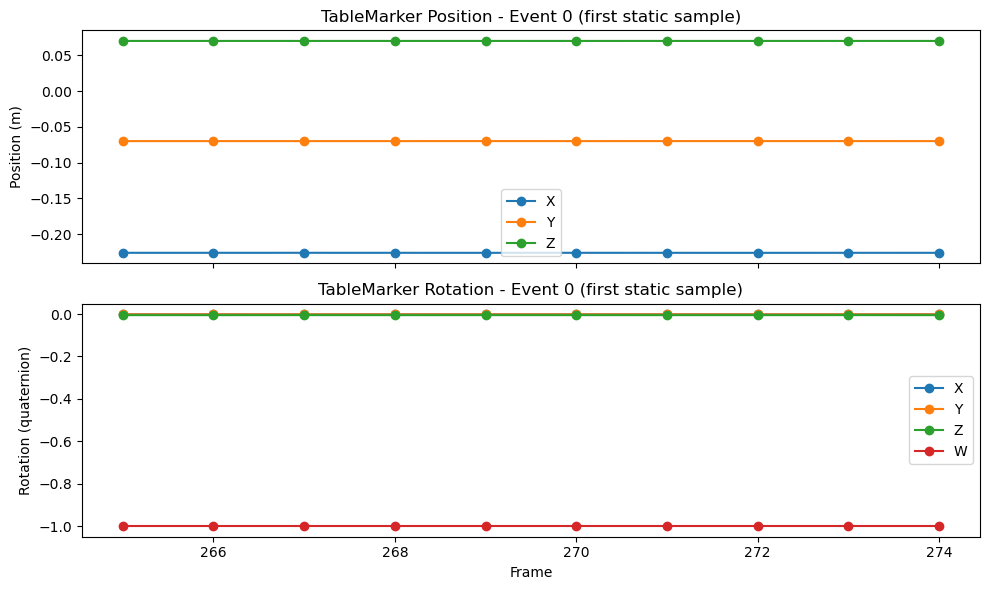

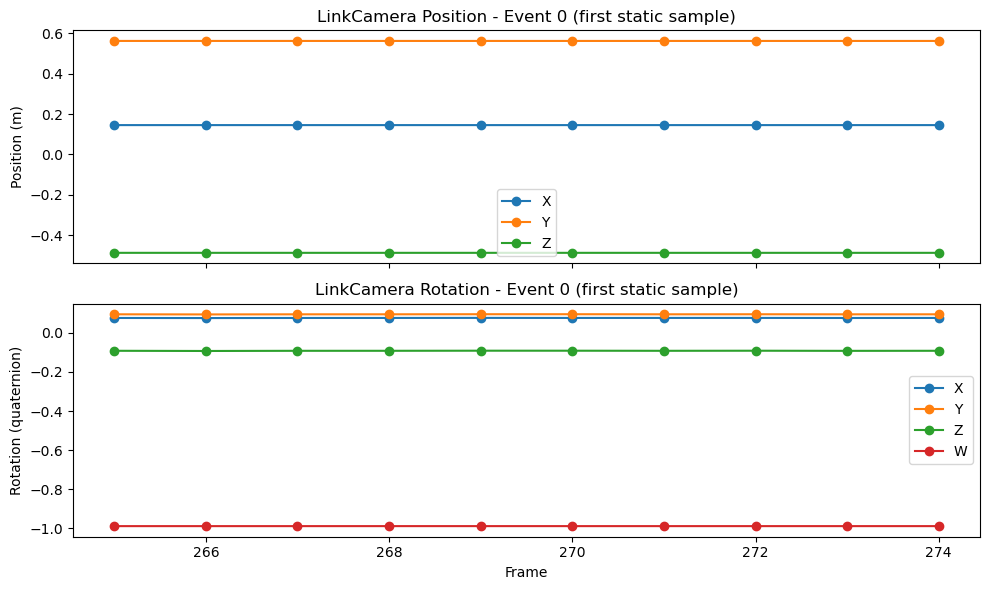

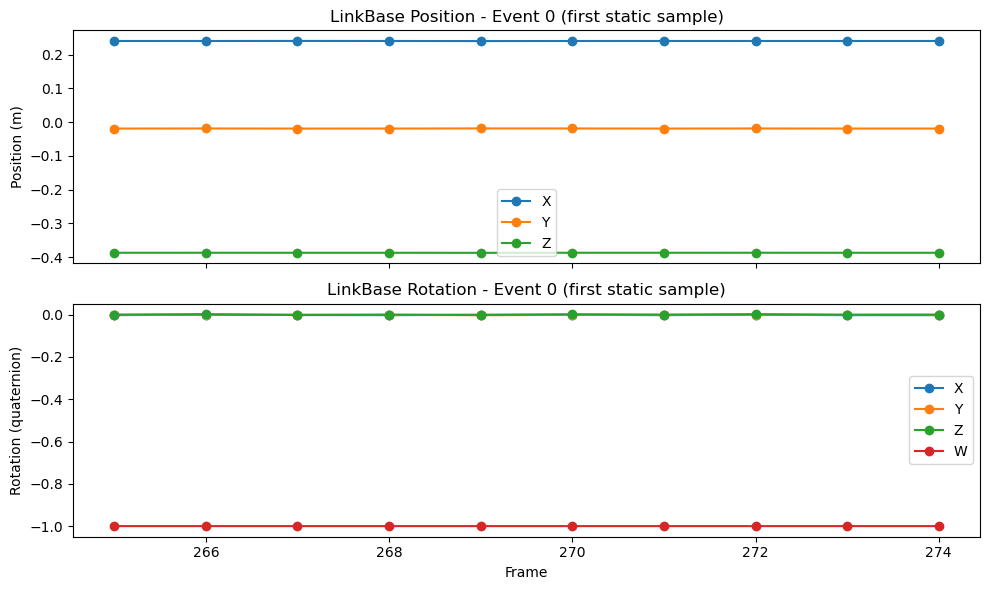

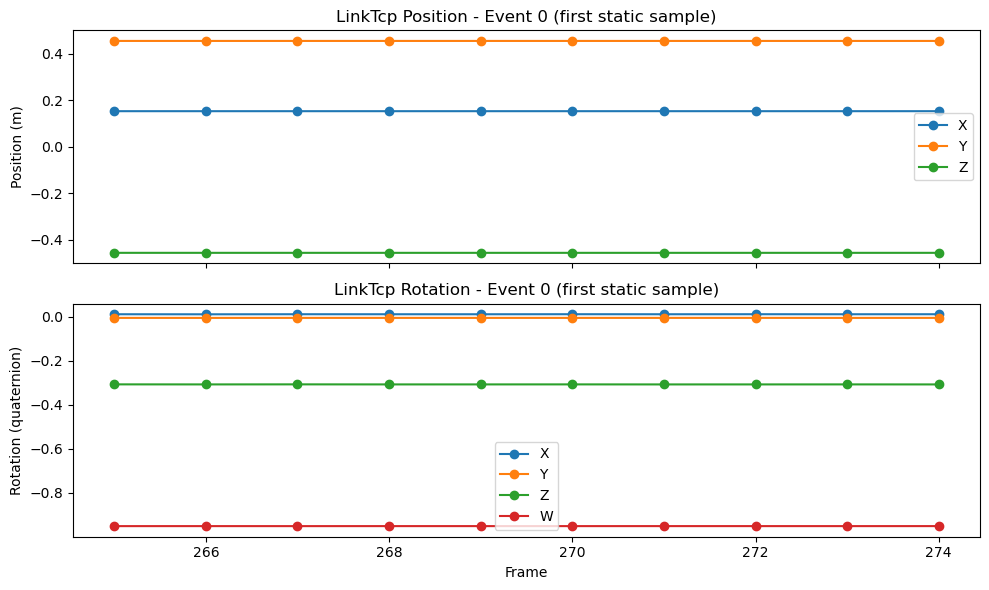

In [12]:
import numpy as np

ALIGNED_CSV_PATH = "trial1_06_aligned_dataset.csv"
BODY_NAMES = ["TableMarker", "LinkCamera", "LinkBase", "LinkTcp"]

needed_cols = ["Frame", "Time_Seconds", "User_Marker"]
for name in BODY_NAMES:
    needed_cols += [f"{name}_Position_{ax}" for ax in "XYZ"]
    needed_cols += [f"{name}_Rotation_{ax}" for ax in "XYZW"]

event_df = pd.read_csv(ALIGNED_CSV_PATH, usecols=needed_cols)

# Group consecutive User_Marker == 1 rows into distinct static-sample events
# (the dataset holds 25 such events, ~10 samples each).
marker_idx = np.flatnonzero((event_df["User_Marker"] == 1).to_numpy())
event_groups = []
run = [marker_idx[0]]
for i in marker_idx[1:]:
    if i == run[-1] + 1:
        run.append(i)
    else:
        event_groups.append(run)
        run = [i]
event_groups.append(run)

print(f"Found {len(event_groups)} events ({[len(g) for g in event_groups]})")

# First event only.
first_event_df = event_df.loc[event_groups[0]]
print(f"Event 0: {len(first_event_df)} samples, Frame "
      f"{first_event_df['Frame'].iloc[0]}-{first_event_df['Frame'].iloc[-1]}")

# One Position/Rotation figure per rigid body, first event only.
for name in BODY_NAMES:
    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

    for axis in "XYZ":
        axes[0].plot(first_event_df["Frame"].to_numpy(), first_event_df[f"{name}_Position_{axis}"].to_numpy(),
                      marker="o", label=axis)
    axes[0].set_ylabel("Position (m)")
    axes[0].set_title(f"{name} Position - Event 0 (first static sample)")
    axes[0].legend()

    for axis in "XYZW":
        axes[1].plot(first_event_df["Frame"].to_numpy(), first_event_df[f"{name}_Rotation_{axis}"].to_numpy(),
                      marker="o", label=axis)
    axes[1].set_xlabel("Frame")
    axes[1].set_ylabel("Rotation (quaternion)")
    axes[1].set_title(f"{name} Rotation - Event 0 (first static sample)")
    axes[1].legend()

    plt.tight_layout()
    plt.show()


In [ ]:
def average_quaternions(quats):
    """Average unit quaternions (Nx4, xyzw), handling the +/-q sign ambiguity."""
    quats = np.asarray(quats, dtype=float)
    ref = quats[0]
    signs = np.sign(quats @ ref)
    signs[signs == 0] = 1
    mean_q = (quats * signs[:, None]).mean(axis=0)
    return mean_q / np.linalg.norm(mean_q)


event_avg_rows = []
for event_id, group_idx in enumerate(event_groups):
    group_df = event_df.loc[group_idx]
    row = {
        "event_id": event_id,
        "num_samples": len(group_df),
        "start_frame": int(group_df["Frame"].iloc[0]),
        "end_frame": int(group_df["Frame"].iloc[-1]),
        "mean_time": group_df["Time_Seconds"].mean(),
    }

    for name in BODY_NAMES:
        pos_cols = [f"{name}_Position_{ax}" for ax in "XYZ"]
        quat_cols = [f"{name}_Rotation_{ax}" for ax in "XYZW"]
        valid = group_df[group_df[pos_cols + quat_cols].notna().all(axis=1)]
        out_cols = ["Pos_X", "Pos_Y", "Pos_Z", "Quat_X", "Quat_Y", "Quat_Z", "Quat_W"]

        if valid.empty:
            print(f"Event {event_id}: no valid (unoccluded) sample for {name} - averages set to NaN")
            row[f"{name}_num_valid"] = 0
            for out_col in out_cols:
                row[f"{name}_{out_col}"] = np.nan
            continue

        pos = valid[pos_cols].to_numpy().mean(axis=0)
        quat = average_quaternions(valid[quat_cols].to_numpy())

        row[f"{name}_num_valid"] = len(valid)
        for out_col, val in zip(out_cols, list(pos) + list(quat)):
            row[f"{name}_{out_col}"] = val

    event_avg_rows.append(row)

event_avg_df = pd.DataFrame(event_avg_rows)
event_avg_df.to_csv("trial1_06_event_average_poses.csv", index=False)
print(f"Computed average pose for {len(event_avg_df)} events -> trial1_06_event_average_poses.csv")
event_avg_df

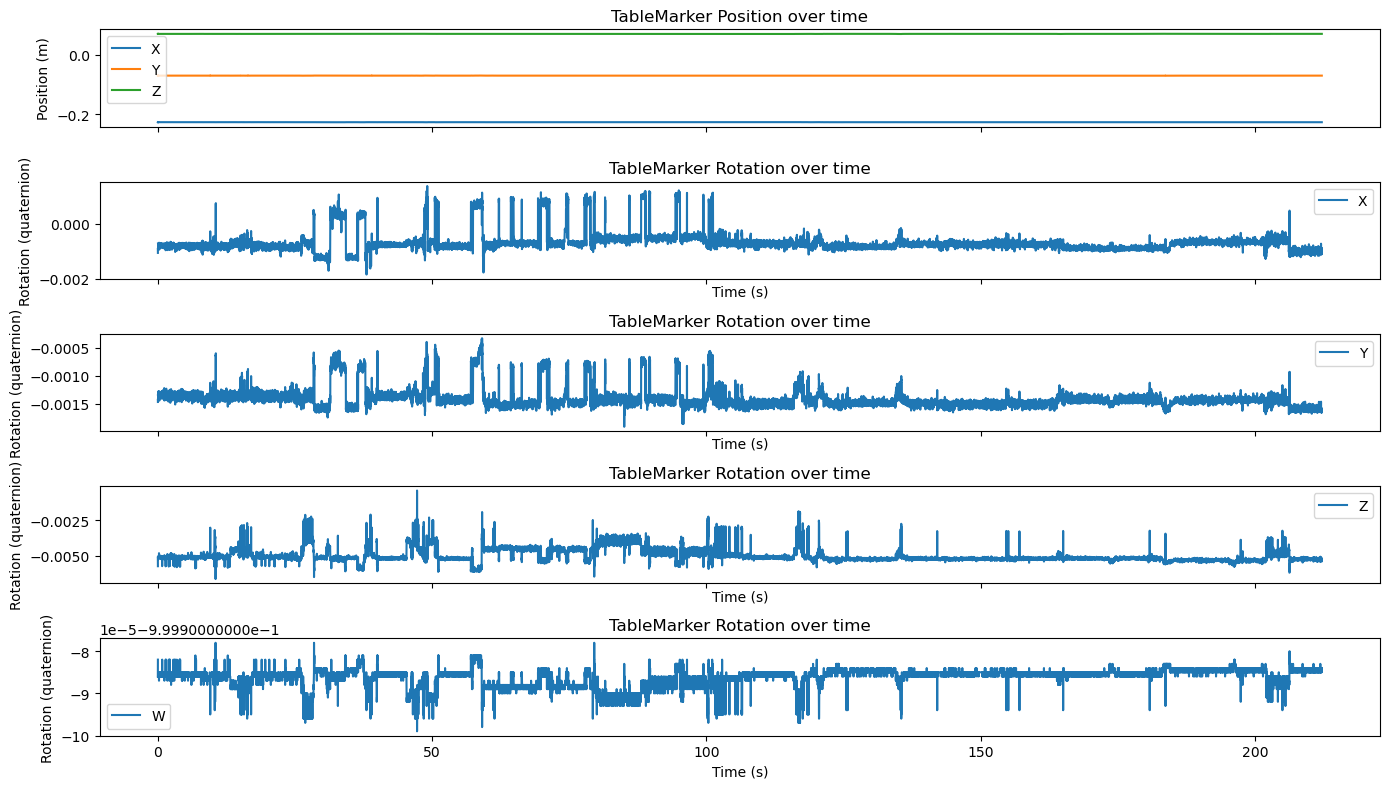

In [ ]:
tm_df = pd.read_csv("trial1_06_aligned_dataset.csv")

fig, axes = plt.subplots(5, 1, figsize=(14, 8), sharex=True)

axes[0].plot(tm_df["Time_Seconds"].to_numpy(), tm_df["TableMarker_Position_X"].to_numpy(), label="X")
axes[0].plot(tm_df["Time_Seconds"].to_numpy(), tm_df["TableMarker_Position_Y"].to_numpy(), label="Y")
axes[0].plot(tm_df["Time_Seconds"].to_numpy(), tm_df["TableMarker_Position_Z"].to_numpy(), label="Z")
axes[0].set_ylabel("Position (m)")
axes[0].set_title("TableMarker Position over time")
axes[0].legend()

axes[1].plot(tm_df["Time_Seconds"].to_numpy(), tm_df["TableMarker_Rotation_X"].to_numpy(), label="X")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Rotation (quaternion)")
axes[1].set_title("TableMarker Rotation over time")
axes[1].legend()

axes[2].plot(tm_df["Time_Seconds"].to_numpy(), tm_df["TableMarker_Rotation_Y"].to_numpy(), label="Y")
axes[2].set_xlabel("Time (s)")
axes[2].set_ylabel("Rotation (quaternion)")
axes[2].set_title("TableMarker Rotation over time")
axes[2].legend()

axes[3].plot(tm_df["Time_Seconds"].to_numpy(), tm_df["TableMarker_Rotation_Z"].to_numpy(), label="Z")
axes[3].set_xlabel("Time (s)")
axes[3].set_ylabel("Rotation (quaternion)")
axes[3].set_title("TableMarker Rotation over time")
axes[3].legend()

axes[4].plot(tm_df["Time_Seconds"].to_numpy(), tm_df["TableMarker_Rotation_W"].to_numpy(), label="W")
axes[4].set_xlabel("Time (s)")
axes[4].set_ylabel("Rotation (quaternion)")
axes[4].set_title("TableMarker Rotation over time")
axes[4].legend()

plt.tight_layout()
plt.show()

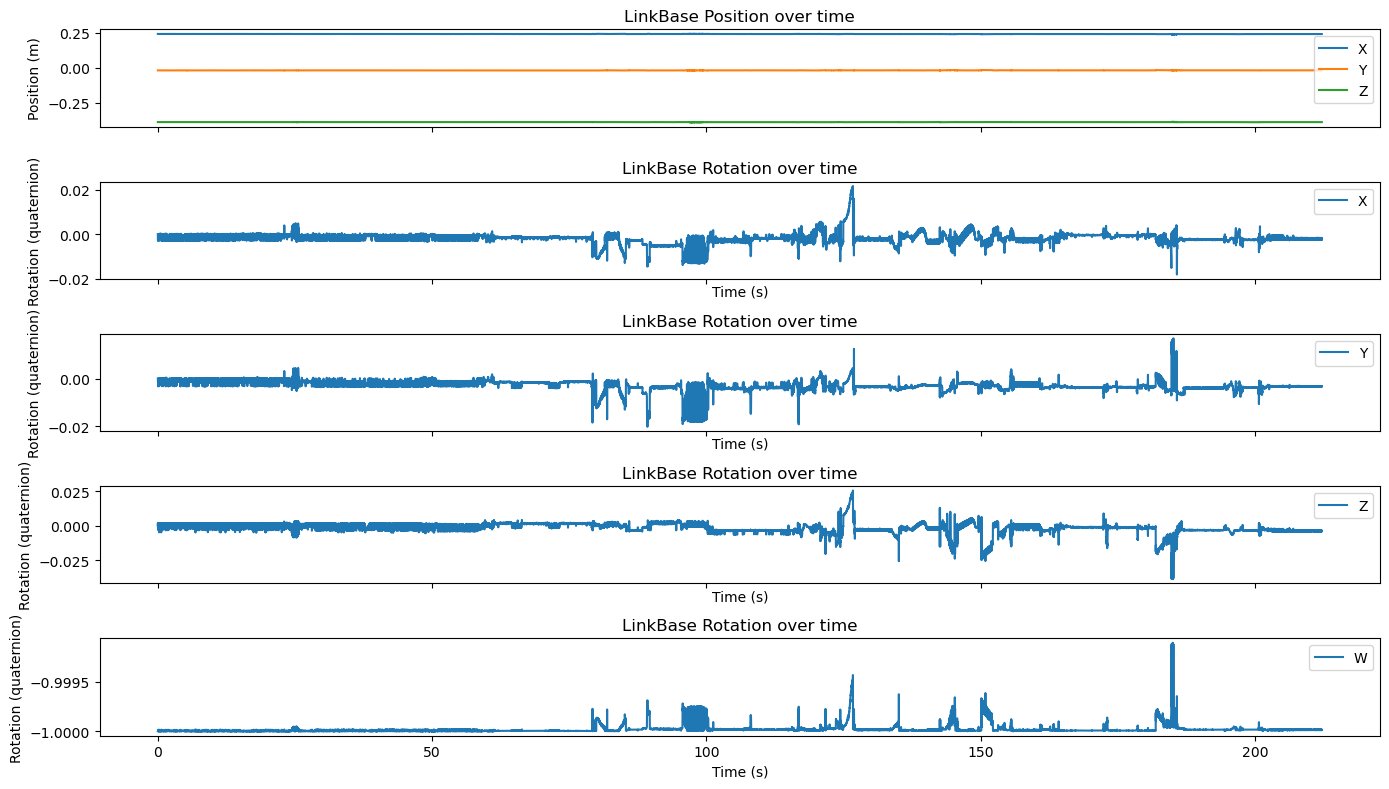

In [ ]:
lb_df = pd.read_csv("trial1_06_aligned_dataset.csv")

fig, axes = plt.subplots(5, 1, figsize=(14, 8), sharex=True)

axes[0].plot(lb_df["Time_Seconds"].to_numpy(), lb_df["LinkBase_Position_X"].to_numpy(), label="X")
axes[0].plot(lb_df["Time_Seconds"].to_numpy(), lb_df["LinkBase_Position_Y"].to_numpy(), label="Y")
axes[0].plot(lb_df["Time_Seconds"].to_numpy(), lb_df["LinkBase_Position_Z"].to_numpy(), label="Z")
axes[0].set_ylabel("Position (m)")
axes[0].set_title("LinkBase Position over time")
axes[0].legend()

axes[1].plot(lb_df["Time_Seconds"].to_numpy(), lb_df["LinkBase_Rotation_X"].to_numpy(), label="X")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Rotation (quaternion)")
axes[1].set_title("LinkBase Rotation over time")
axes[1].legend()

axes[2].plot(lb_df["Time_Seconds"].to_numpy(), lb_df["LinkBase_Rotation_Y"].to_numpy(), label="Y")
axes[2].set_xlabel("Time (s)")
axes[2].set_ylabel("Rotation (quaternion)")
axes[2].set_title("LinkBase Rotation over time")
axes[2].legend()

axes[3].plot(lb_df["Time_Seconds"].to_numpy(), lb_df["LinkBase_Rotation_Z"].to_numpy(), label="Z")
axes[3].set_xlabel("Time (s)")
axes[3].set_ylabel("Rotation (quaternion)")
axes[3].set_title("LinkBase Rotation over time")
axes[3].legend()

axes[4].plot(lb_df["Time_Seconds"].to_numpy(), lb_df["LinkBase_Rotation_W"].to_numpy(), label="W")
axes[4].set_xlabel("Time (s)")
axes[4].set_ylabel("Rotation (quaternion)")
axes[4].set_title("LinkBase Rotation over time")
axes[4].legend()

plt.tight_layout()
plt.show()

In [ ]:
import cv2
from scipy.spatial.transform import Rotation as Rot



def pose_to_matrix(pos, quat_xyzw):
    T = np.eye(4)
    T[:3, :3] = Rot.from_quat(quat_xyzw).as_matrix()
    T[:3, 3] = pos
    return T


POSE_COLS = {
    name: (
        [f"{name}_Pos_X", f"{name}_Pos_Y", f"{name}_Pos_Z"],
        [f"{name}_Quat_X", f"{name}_Quat_Y", f"{name}_Quat_Z", f"{name}_Quat_W"],
    )
    for name in BODY_NAMES
}

# Only events where all 4 bodies were visible give a usable ground-truth
# transform (dropped 4/25 occluded events -> 21 valid samples).
all_pose_cols = [c for cols in POSE_COLS.values() for c in cols[0] + cols[1]]
valid_events_df = event_avg_df.dropna(subset=all_pose_cols).reset_index(drop=True)
print(f"Valid events (all 4 bodies visible): {len(valid_events_df)} / {len(event_avg_df)}")

R_gripper2base, t_gripper2base = [], []
R_target2cam, t_target2cam = [], []
T_tool_camera_gt_list = []

for _, row in valid_events_df.iterrows():
    T_world = {}
    for name in BODY_NAMES:
        pos_cols, quat_cols = POSE_COLS[name]
        T_world[name] = pose_to_matrix(row[pos_cols].to_numpy(dtype=float), row[quat_cols].to_numpy(dtype=float))

    T_base_tool = np.linalg.inv(T_world["LinkBase"]) @ T_world["LinkTcp"]
    T_cam_marker = np.linalg.inv(T_world["LinkCamera"]) @ T_world["TableMarker"]
    T_tool_camera_gt = np.linalg.inv(T_world["LinkTcp"]) @ T_world["LinkCamera"]

    R_gripper2base.append(T_base_tool[:3, :3])
    t_gripper2base.append(T_base_tool[:3, 3].reshape(3, 1))
    R_target2cam.append(T_cam_marker[:3, :3])
    t_target2cam.append(T_cam_marker[:3, 3].reshape(3, 1))
    T_tool_camera_gt_list.append(T_tool_camera_gt)

R_cam2gripper, t_cam2gripper = cv2.calibrateHandEye(
    R_gripper2base, t_gripper2base, R_target2cam, t_target2cam,
    method=cv2.CALIB_HAND_EYE_TSAI,
)
T_tool_camera_he = np.eye(4)
T_tool_camera_he[:3, :3] = R_cam2gripper
T_tool_camera_he[:3, 3] = t_cam2gripper.ravel()

print("Tool_T_Camera_HE translation (m):", t_cam2gripper.ravel())
print("Tool_T_Camera_HE quaternion (xyzw):", Rot.from_matrix(R_cam2gripper).as_quat())

# Per-event error between the ground-truth transform and the constant HE estimate.
error_rows = []
for event_id, T_gt in zip(valid_events_df["event_id"], T_tool_camera_gt_list):
    translation_error_mm = np.linalg.norm(T_gt[:3, 3] - T_tool_camera_he[:3, 3]) * 1000
    R_rel = T_tool_camera_he[:3, :3].T @ T_gt[:3, :3]
    rotation_error_deg = np.linalg.norm(Rot.from_matrix(R_rel).as_rotvec()) * 180 / np.pi
    error_rows.append({
        "event_id": event_id,
        "translation_error_mm": translation_error_mm,
        "rotation_error_deg": rotation_error_deg,
    })

validation_df = pd.DataFrame(error_rows)
validation_df.to_csv("trial1_06_handeye_validation.csv", index=False)

print(f"\nTranslation error (mm): mean={validation_df['translation_error_mm'].mean():.3f} "
      f"std={validation_df['translation_error_mm'].std():.3f} max={validation_df['translation_error_mm'].max():.3f}")
print(f"Rotation error (deg):   mean={validation_df['rotation_error_deg'].mean():.3f} "
      f"std={validation_df['rotation_error_deg'].std():.3f} max={validation_df['rotation_error_deg'].max():.3f}")

validation_df


Valid events (all 4 bodies visible): 21 / 25
Tool_T_Camera_HE translation (m): [ 0.05616263  0.08949483 -0.02895328]
Tool_T_Camera_HE quaternion (xyzw): [-0.10354307 -0.07976612 -0.22398591  0.96578802]

Translation error (mm): mean=3.090 std=1.369 max=5.814
Rotation error (deg):   mean=1.972 std=0.742 max=3.462


,event_id,translation_error_mm,rotation_error_deg
0,0,2.386711,1.703649
1,1,4.354808,2.411150
2,3,2.837363,1.156687
3,4,2.186073,2.471703
4,5,2.536772,1.728143
5,6,1.597881,1.181255
6,7,4.778538,1.374310
7,8,3.540987,3.119013
8,9,4.670296,1.959874
9,10,5.814035,0.412570


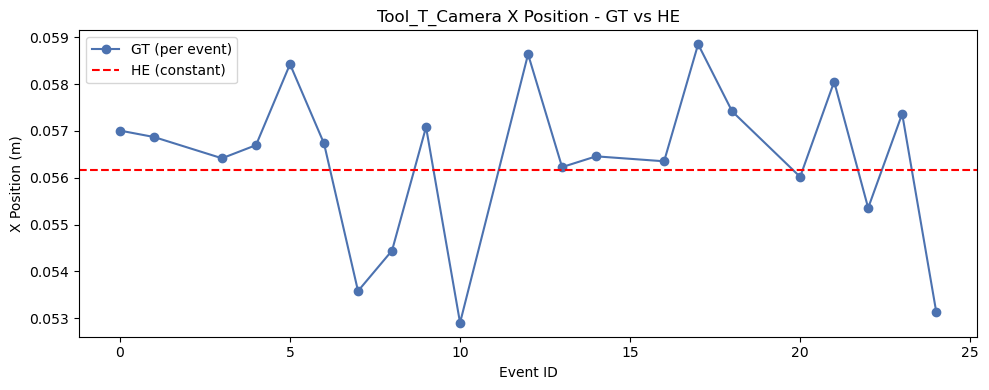

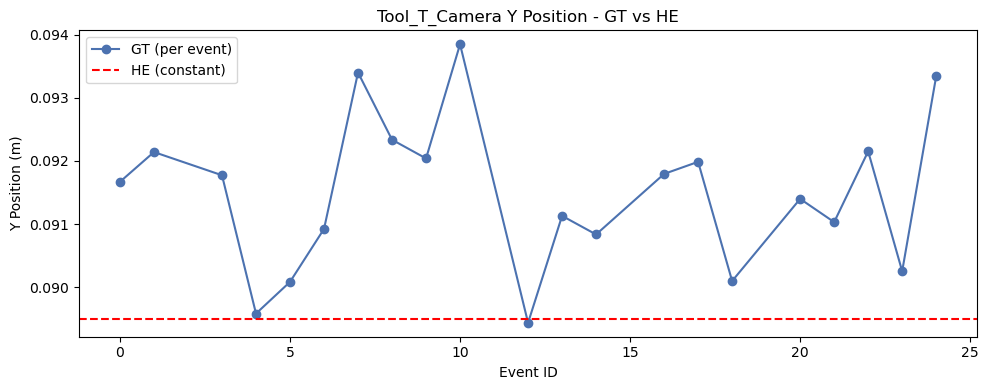

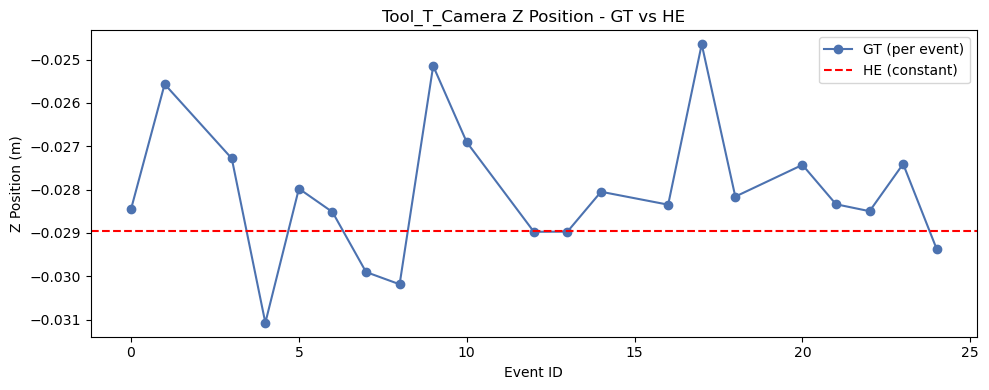

In [21]:

gt_event_ids = valid_events_df["event_id"].to_numpy()
gt_positions = np.array([T[:3, 3] for T in T_tool_camera_gt_list])
gt_eulers_deg = np.array([Rot.from_matrix(T[:3, :3]).as_euler("xyz", degrees=True) for T in T_tool_camera_gt_list])

he_position = T_tool_camera_he[:3, 3]
he_euler_deg = Rot.from_matrix(T_tool_camera_he[:3, :3]).as_euler("xyz", degrees=True)

for axis_idx, axis_label in enumerate("XYZ"):
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(gt_event_ids, gt_positions[:, axis_idx], marker="o", color="#4C72B0", label="GT (per event)")
    ax.axhline(he_position[axis_idx], color="red", linestyle="--", label="HE (constant)")
    ax.set_xlabel("Event ID")
    ax.set_ylabel(f"{axis_label} Position (m)")
    ax.set_title(f"Tool_T_Camera {axis_label} Position - GT vs HE")
    ax.legend()
    plt.tight_layout()
    plt.show()

# fig, ax = plt.subplots(figsize=(10, 4))
# euler_colors = {"Roll": "#4C72B0", "Pitch": "#DD8452", "Yaw": "#55A868"}
# for axis_idx, axis_label in enumerate(["Roll", "Pitch", "Yaw"]):
#     color = euler_colors[axis_label]
#     ax.plot(gt_event_ids, gt_eulers_deg[:, axis_idx], marker="o", color=color, label=f"{axis_label} GT")
#     ax.axhline(he_euler_deg[axis_idx], color=color, linestyle="--", label=f"{axis_label} HE")
# ax.set_xlabel("Event ID")
# ax.set_ylabel("Rotation (deg)")
# ax.set_title("Tool_T_Camera Rotation (Euler XYZ) - GT vs HE")
# ax.legend(ncol=3)
# plt.tight_layout()
# plt.show()




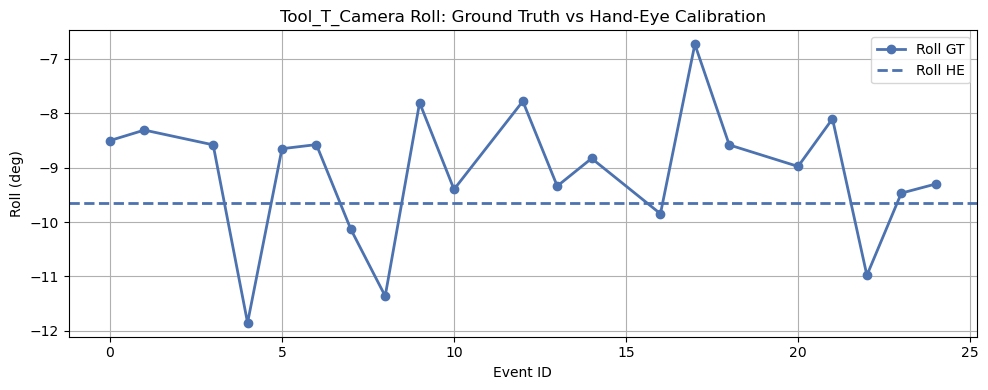

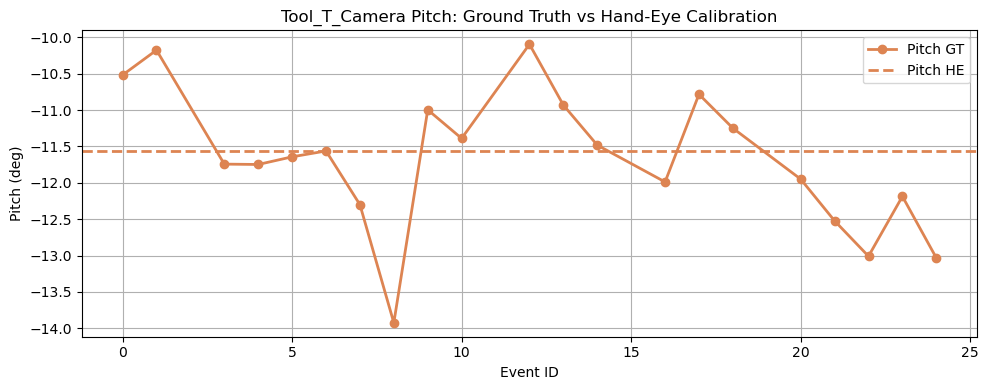

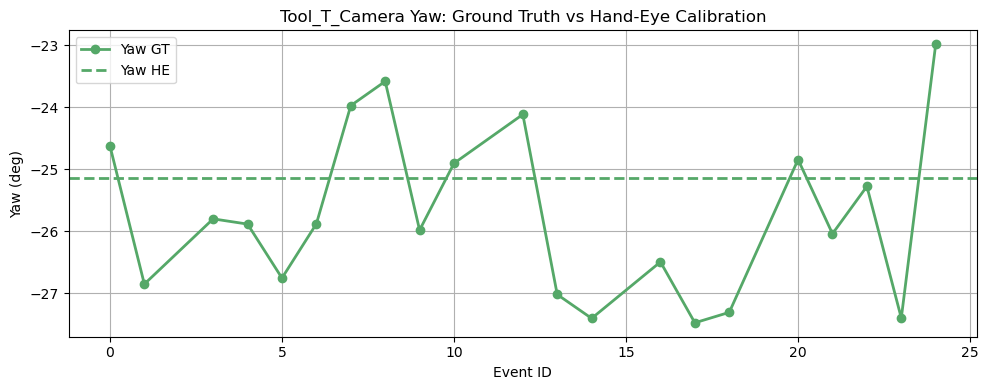

In [20]:
euler_colors = {
    "Roll": "#4C72B0",
    "Pitch": "#DD8452",
    "Yaw": "#55A868"
}

euler_labels = ["Roll", "Pitch", "Yaw"]

for axis_idx, axis_label in enumerate(euler_labels):

    plt.figure(figsize=(10, 4))

    color = euler_colors[axis_label]

    plt.plot(
        gt_event_ids,
        gt_eulers_deg[:, axis_idx],
        marker="o",
        linewidth=2,
        color=color,
        label=f"{axis_label} GT"
    )

    plt.axhline(
        he_euler_deg[axis_idx],
        color=color,
        linestyle="--",
        linewidth=2,
        label=f"{axis_label} HE"
    )

    plt.xlabel("Event ID")
    plt.ylabel(f"{axis_label} (deg)")
    plt.title(f"Tool_T_Camera {axis_label}: Ground Truth vs Hand-Eye Calibration")
    plt.grid(True)
    plt.legend()

    plt.tight_layout()
    plt.show()